<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · What survives a BSON–JSON round trip?

**Can a displayed value stay the same while its BSON type changes?**
We will encode twelve synthetic typed documents, render canonical and relaxed
Extended JSON, and decode both representations back to BSON through VGI.
SQL compares leaf values, leaf types and complete document bytes. Two charts
show the selected mode's fidelity and the size of each JSON representation.

These are constructed examples, not a production dump or a throughput benchmark.
The comparison measures the pinned worker's behavior on these exact inputs.

## Choose the round trip to inspect

`JSON_MODE` accepts **`canonical`** or **`relaxed`**. Default **`canonical`**;
experiment **`relaxed`**. We calculate both reference paths each time, then use
this parameter to select the detailed table, fidelity matrix and outlined bars.
Restart the kernel and run all after editing.

In [1]:
JSON_MODE = "canonical"

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import ListedColormap
from notebook_support import finish, prose, theme

if JSON_MODE not in {"canonical", "relaxed"}:
    raise ValueError("JSON_MODE must be canonical or relaxed.")
MODE_COLORS = {"canonical": "#456fba", "relaxed": "#8e81a5"}
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-bson/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-bson/notebooks/pyproject.toml.

## Connect to the public codec release

VGI downloads, verifies and caches the native **v0.4.0** release for this platform.
The notebook uses the public release and its scalar codecs; no local worker build
or MongoDB server is needed. The Python environment locks Haybarn **2.0.0rc11**.
Initial installation needs network access; the analysis uses only local bytes.

The first control makes the difference in number wrappers visible.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'bson' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-bson@v0.4.0');
SELECT bson.main.to_json(bson.main.from_json('{"value":{"$numberLong":"7"}}'), 'canonical') AS canonical_json,
       bson.main.to_json(bson.main.from_json('{"value":{"$numberLong":"7"}}'), 'relaxed') AS relaxed_json;

,canonical_json,relaxed_json
0,"{""value"":{""$numberLong"":""7""}}","{""value"":7}"


## Build a small type inventory

The inputs explicitly declare Int32, Int64, Double and Decimal128, alongside
dates, ObjectId, binary, internal Timestamp, null and a nested Int64 field.
The BSON date and internal Timestamp are separate types; we do not collapse
them into a common clock value. NaN and Decimal128 retain Extended JSON wrappers
in relaxed output too.

`from_json` interprets these wrappers and constructs BSON. We keep the originals
as BLOBs so the final check can compare complete bytes, not just formatted text.

In [5]:
%%sql
CREATE OR REPLACE TABLE examples AS
SELECT * FROM (VALUES
 (1, 'Int32 7', 'value', '{"value":{"$numberInt":"7"}}'),
 (2, 'Int64 7', 'value', '{"value":{"$numberLong":"7"}}'),
 (3, 'Int64 2^31', 'value', '{"value":{"$numberLong":"2147483648"}}'),
 (4, 'Double 7.0', 'value', '{"value":{"$numberDouble":"7.0"}}'),
 (5, 'Double NaN', 'value', '{"value":{"$numberDouble":"NaN"}}'),
 (6, 'Decimal128', 'value', '{"value":{"$numberDecimal":"12345678901234567890.1234"}}'),
 (7, 'Date (milliseconds)', 'value', '{"value":{"$date":{"$numberLong":"1704067200123"}}}'),
 (8, 'ObjectId', 'value', '{"value":{"$oid":"659200800000000000000001"}}'),
 (9, 'Binary subtype 00', 'value', '{"value":{"$binary":{"base64":"AQIDBA==","subType":"00"}}}'),
 (10, 'Internal Timestamp', 'value', '{"value":{"$timestamp":{"t":1704067200,"i":7}}}'),
 (11, 'Explicit null', 'value', '{"value":null}'),
 (12, 'Nested Int64 7', 'nested.count', '{"nested":{"count":{"$numberLong":"7"}}}')
) t(id, label, field_path, source_json);
CREATE OR REPLACE TABLE originals AS
SELECT *, bson.main.from_json(source_json) AS doc FROM examples;
SELECT id, label, field_path, source_json, octet_length(doc) AS bson_bytes
FROM originals ORDER BY id;

,id,label,field_path,source_json,bson_bytes
0,1,Int32 7,value,"{""value"":{""$numberInt"":""7""}}",16
1,2,Int64 7,value,"{""value"":{""$numberLong"":""7""}}",20
2,3,Int64 2^31,value,"{""value"":{""$numberLong"":""2147483648""}}",20
3,4,Double 7.0,value,"{""value"":{""$numberDouble"":""7.0""}}",20
4,5,Double NaN,value,"{""value"":{""$numberDouble"":""NaN""}}",20
5,6,Decimal128,value,"{""value"":{""$numberDecimal"":""123456789012345678...",28
6,7,Date (milliseconds),value,"{""value"":{""$date"":{""$numberLong"":""170406720012...",20
7,8,ObjectId,value,"{""value"":{""$oid"":""659200800000000000000001""}}",24
8,9,Binary subtype 00,value,"{""value"":{""$binary"":{""base64"":""AQIDBA=="",""subT...",21
9,10,Internal Timestamp,value,"{""value"":{""$timestamp"":{""t"":1704067200,""i"":7}}}",20


## Materialize both representations and their restored bytes

The worker binds `to_json`'s mode as a constant, so each UNION branch supplies a
literal mode. The same rule applies to field paths below: the nested example
uses its own literal path. This keeps SQL compatible with the released interface.

Canonical Extended JSON keeps explicit numeric wrappers. Relaxed output can use
plain JSON numbers where possible. Parsing a plain `7` back does not carry an
Int64-width instruction, which is the distinction we will measure.

In [6]:
%%sql
CREATE OR REPLACE TABLE rendered AS
SELECT *, 'canonical' AS mode, bson.main.to_json(doc, 'canonical') AS extjson FROM originals
UNION ALL
SELECT *, 'relaxed', bson.main.to_json(doc, 'relaxed') FROM originals;
CREATE OR REPLACE TABLE restored AS
SELECT *, bson.main.from_json(extjson) AS restored_doc,
       octet_length(encode(extjson)) AS json_utf8_bytes FROM rendered;
CREATE OR REPLACE TABLE measured AS
SELECT *,
       CASE WHEN field_path = 'nested.count' THEN bson.main.type_of(doc, 'nested.count') ELSE bson.main.type_of(doc, 'value') END AS original_type,
       CASE WHEN field_path = 'nested.count' THEN bson.main.type_of(restored_doc, 'nested.count') ELSE bson.main.type_of(restored_doc, 'value') END AS restored_type,
       CASE WHEN field_path = 'nested.count' THEN bson.main.field(doc, 'nested.count') ELSE bson.main.field(doc, 'value') END AS original_value,
       CASE WHEN field_path = 'nested.count' THEN bson.main.field(restored_doc, 'nested.count') ELSE bson.main.field(restored_doc, 'value') END AS restored_value
FROM restored;
SELECT id, label, mode, extjson FROM measured WHERE id IN (2,6,7,12) ORDER BY id, mode;

,id,label,mode,extjson
0,2,Int64 7,canonical,"{""value"":{""$numberLong"":""7""}}"
1,2,Int64 7,relaxed,"{""value"":7}"
2,6,Decimal128,canonical,"{""value"":{""$numberDecimal"":""123456789012345678..."
3,6,Decimal128,relaxed,"{""value"":{""$numberDecimal"":""123456789012345678..."
4,7,Date (milliseconds),canonical,"{""value"":{""$date"":{""$numberLong"":""170406720012..."
5,7,Date (milliseconds),relaxed,"{""value"":{""$date"":""2024-01-01T00:00:00.123Z""}}"
6,12,Nested Int64 7,canonical,"{""nested"":{""count"":{""$numberLong"":""7""}}}"
7,12,Nested Int64 7,relaxed,"{""nested"":{""count"":7}}"


## Separate codec integrity from the mode's tradeoff

The checks establish valid input/output documents, complete mode coverage and
exact canonical round trips for this constructed corpus. Relaxed round trips
are measured rather than assumed to preserve all types.

We compare complete BLOBs directly. A matching leaf string is weaker evidence:
it can hide a numeric-width change, or say nothing about other fields and order.

In [7]:
%%sql checks <<
SELECT 'Original documents are well formed' AS check_name,
       count(*) FILTER (WHERE (bson.main.well_formed(doc)).ok IS DISTINCT FROM TRUE) AS violations FROM originals
UNION ALL
SELECT 'Both modes render and restore every document', count(*) FROM measured
 WHERE extjson IS NULL OR restored_doc IS NULL OR (bson.main.well_formed(restored_doc)).ok IS DISTINCT FROM TRUE
UNION ALL
SELECT 'Exactly one result per input and mode', count(*) FROM (
 SELECT id, mode FROM measured GROUP BY id, mode HAVING count(*) <> 1
)
UNION ALL
SELECT 'Both mode branches have full coverage', abs(count(*) - 2 * (SELECT count(*) FROM originals)) FROM measured
UNION ALL
SELECT 'Canonical round trip preserves complete fixture bytes', count(*) FROM measured WHERE mode = 'canonical' AND doc IS DISTINCT FROM restored_doc
UNION ALL
SELECT 'The inspected leaf exists in every fixture', count(*) FROM measured WHERE original_type IS NULL OR restored_type IS NULL;

In [8]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "The codec or fixture-integrity checks failed."
prose(
    f"All **{len(checks)} checks pass**. Canonical output preserves complete BSON bytes for these constructed documents. The next comparison checks how that outcome changes with the selected representation, without treating matching display text as a full migration check."
)

,check_name,violations
0,Original documents are well formed,0
1,Both modes render and restore every document,0
2,Exactly one result per input and mode,0
3,Both mode branches have full coverage,0
4,Canonical round trip preserves complete fixtur...,0
5,The inspected leaf exists in every fixture,0


All **6 checks pass**. Canonical output preserves complete BSON bytes for these constructed documents. The next comparison checks how that outcome changes with the selected representation, without treating matching display text as a full migration check.

In [9]:
%%sql coverage <<
SELECT mode, count(*) AS documents,
       count(*) FILTER (WHERE original_value IS NOT DISTINCT FROM restored_value) AS same_leaf_text,
       count(*) FILTER (WHERE original_type IS NOT DISTINCT FROM restored_type) AS same_leaf_type,
       count(*) FILTER (WHERE doc IS NOT DISTINCT FROM restored_doc) AS same_document_bytes
FROM measured GROUP BY mode ORDER BY mode;

In [10]:
coverage = globals()["coverage"]
display(coverage)
prose(
    "This fixed reference table separates three levels of agreement. Leaf text, BSON leaf type and whole-document bytes answer different questions; a display-oriented check cannot substitute for the latter two."
)

,mode,documents,same_leaf_text,same_leaf_type,same_document_bytes
0,canonical,12,12,12,12
1,relaxed,12,12,10,10


This fixed reference table separates three levels of agreement. Leaf text, BSON leaf type and whole-document bytes answer different questions; a display-oriented check cannot substitute for the latter two.

## Inspect the selected mode at all three levels

The matrix reports equality with the original document. Green means **same**;
amber means **changed**. The leaf-type check targets the declared `field_path`,
including the nested integer. Whole-document equality includes type tags and
field order. All three columns are comparisons, not quality scores.

In [11]:
%%sql selected <<
SELECT id, label, original_type, restored_type, original_value, restored_value,
       original_value IS NOT DISTINCT FROM restored_value AS same_value,
       original_type IS NOT DISTINCT FROM restored_type AS same_type,
       doc IS NOT DISTINCT FROM restored_doc AS same_bytes
FROM measured WHERE mode = '{{ JSON_MODE }}' ORDER BY id;

,label,original_type,restored_type,original_value,restored_value
0,Int32 7,int,int,7,7
1,Int64 7,long,long,7,7
2,Int64 2^31,long,long,2147483648,2147483648
3,Double 7.0,double,double,7,7
4,Double NaN,double,double,NaN,NaN
5,Decimal128,decimal128,decimal128,12345678901234567890.1234,12345678901234567890.1234
6,Date (milliseconds),date,date,2024-01-01T00:00:00.123Z,2024-01-01T00:00:00.123Z
7,ObjectId,objectId,objectId,659200800000000000000001,659200800000000000000001
8,Binary subtype 00,binData:generic,binData:generic,"{""$binary"":{""base64"":""AQIDBA=="",""subType"":""00""}}","{""$binary"":{""base64"":""AQIDBA=="",""subType"":""00""}}"
9,Internal Timestamp,timestamp,timestamp,"{""$timestamp"":{""t"":1704067200,""i"":7}}","{""$timestamp"":{""t"":1704067200,""i"":7}}"


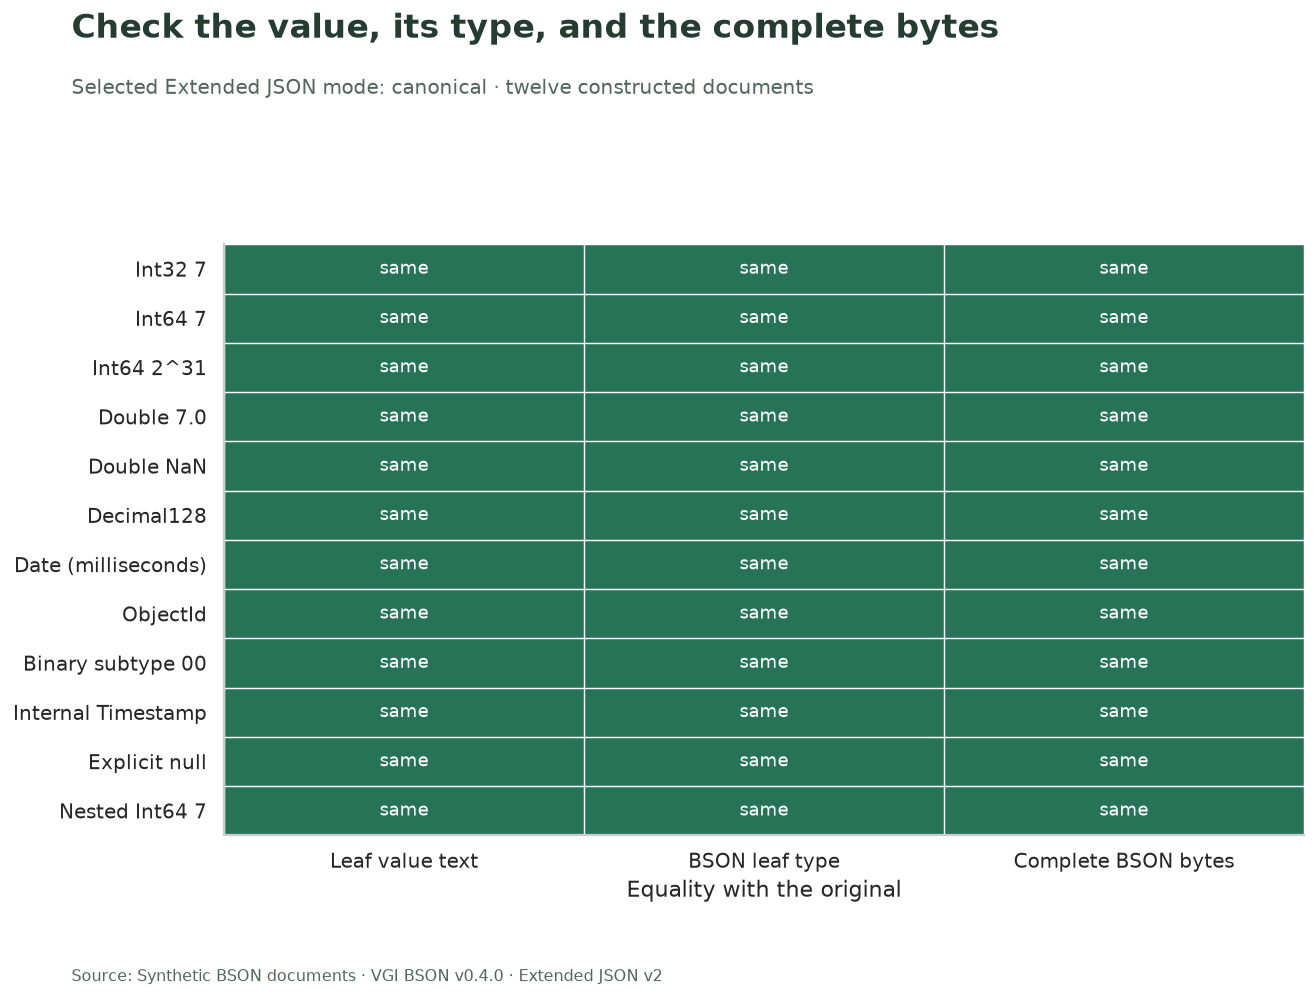

With **canonical** output, **12/12 documents** retain their complete BSON bytes and **0 inspected leaf type(s)** change. No inspected leaf type changes in this selected run.

In [12]:
selected = globals()["selected"]
display(
    selected[
        ["label", "original_type", "restored_type", "original_value", "restored_value"]
    ]
)
values = selected[["same_value", "same_type", "same_bytes"]].to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(10.5, 7.8))
ax.imshow(
    values, cmap=ListedColormap(["#c57b40", "#267358"]), vmin=0, vmax=1, aspect="auto"
)
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(
            j,
            i,
            "same" if values[i, j] else "changed",
            ha="center",
            va="center",
            color="white",
            fontsize=10,
        )
ax.set(
    yticks=np.arange(len(selected)),
    yticklabels=selected.label,
    xticks=[0, 1, 2],
    xticklabels=["Leaf value text", "BSON leaf type", "Complete BSON bytes"],
    xlabel="Equality with the original",
    ylabel="",
)
ax.grid(False)
ax.set_xticks(np.arange(-0.5, 3, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(selected), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="minor", bottom=False, left=False)
finish(
    fig,
    "Check the value, its type, and the complete bytes",
    f"Selected Extended JSON mode: {JSON_MODE} · twelve constructed documents",
    f"fidelity-{JSON_MODE}.png",
)
changed_types = selected[~selected.same_type]
prose(
    f"With **{JSON_MODE}** output, **{int(selected.same_bytes.sum())}/{len(selected)} documents** retain their complete BSON bytes and **{len(changed_types)} inspected leaf type(s)** change. "
    + (
        "Changed examples: **"
        + ", ".join(changed_types.label)
        + "**. Their displayed leaf values remain a separate comparison."
        if len(changed_types)
        else "No inspected leaf type changes in this selected run."
    )
)

## Measure the JSON representation itself

These bars count **UTF-8 bytes in the exact rendered JSON strings**, including
wrappers and punctuation. The outlined mode is selected. Both reference modes
are always shown. We measure neither compressed storage nor encode/decode time.
A smaller string can omit type information that matters to a migration.

In [13]:
%%sql lengths <<
SELECT id, label,
       max(json_utf8_bytes) FILTER (WHERE mode = 'canonical') AS canonical_bytes,
       max(json_utf8_bytes) FILTER (WHERE mode = 'relaxed') AS relaxed_bytes
FROM measured GROUP BY id, label ORDER BY id;

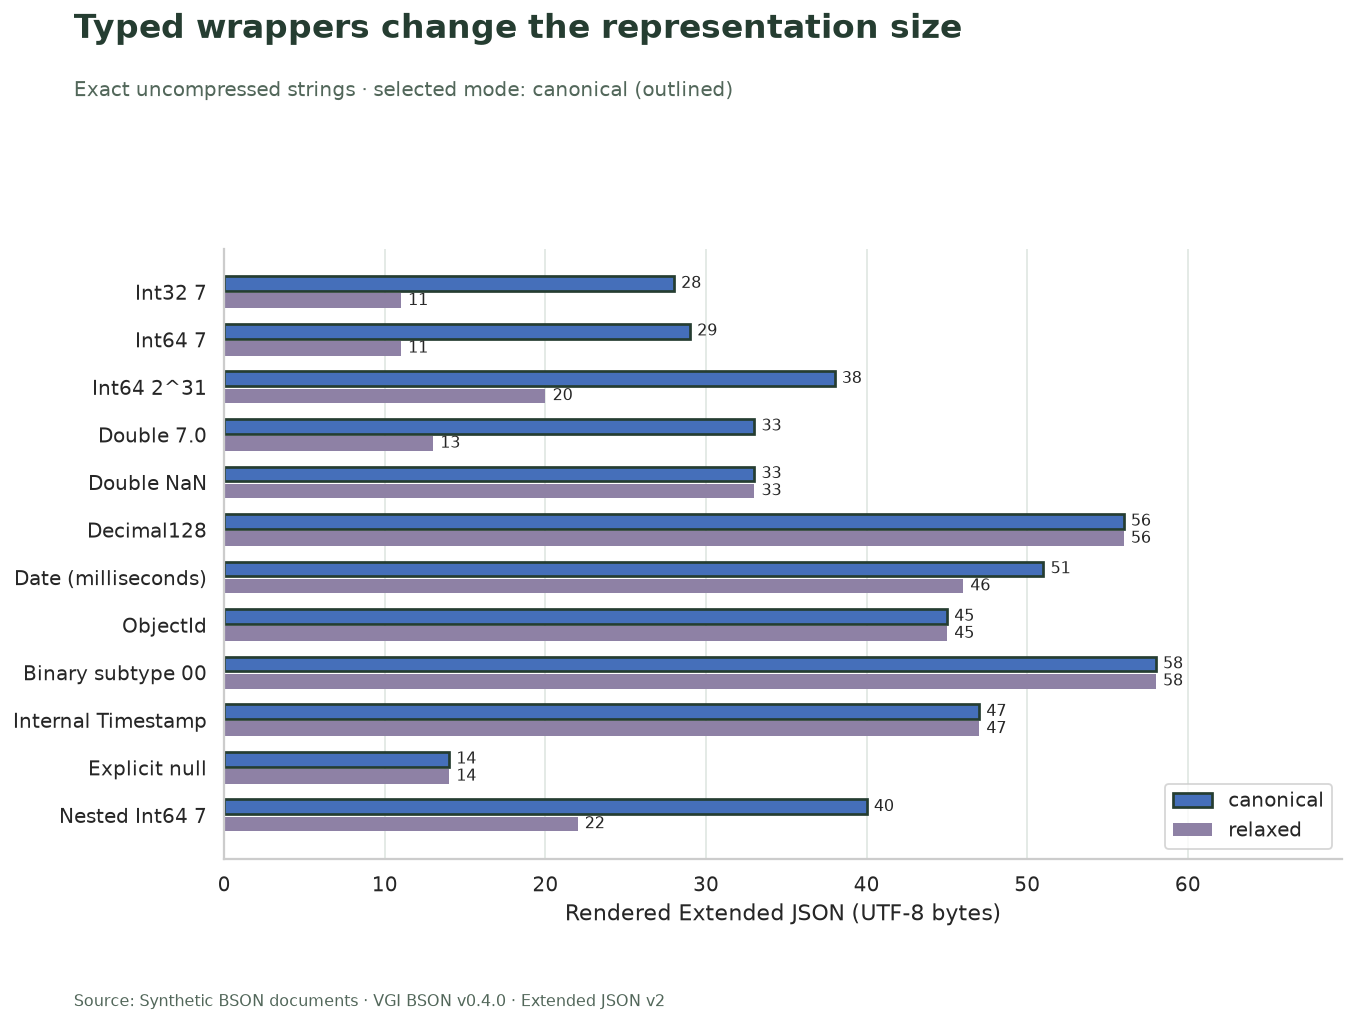

Across this corpus, canonical JSON occupies **472 bytes** and relaxed JSON **376 bytes**. Some rows are identical in size because their type wrappers remain necessary in both modes. This total is specific to these twelve small documents.

In [14]:
lengths = globals()["lengths"]
y = np.arange(len(lengths))
fig, ax = plt.subplots(figsize=(10.8, 8.0))
for offset, mode in zip((-0.18, 0.18), ("canonical", "relaxed"), strict=True):
    bars = ax.barh(
        y + offset,
        lengths[f"{mode}_bytes"],
        height=0.31,
        color=MODE_COLORS[mode],
        edgecolor="#253d31" if mode == JSON_MODE else "none",
        linewidth=1.5,
        label=mode,
    )
    ax.bar_label(bars, padding=4, fontsize=9)
ax.set(
    yticks=y,
    yticklabels=lengths.label,
    xlabel="Rendered Extended JSON (UTF-8 bytes)",
    ylabel="",
)
ax.invert_yaxis()
ax.set_xlim(0, lengths[["canonical_bytes", "relaxed_bytes"]].to_numpy().max() * 1.2)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=True)
finish(
    fig,
    "Typed wrappers change the representation size",
    f"Exact uncompressed strings · selected mode: {JSON_MODE} (outlined)",
    f"sizes-{JSON_MODE}.png",
)
prose(
    f"Across this corpus, canonical JSON occupies **{int(lengths.canonical_bytes.sum())} bytes** and relaxed JSON **{int(lengths.relaxed_bytes.sum())} bytes**. Some rows are identical in size because their type wrappers remain necessary in both modes. This total is specific to these twelve small documents."
)

## Canonical Extended JSON still preserves document order

Here, *canonical* refers to type-aware Extended JSON formatting. It does not sort
BSON document keys into a universal content hash. Two documents with the same
named fields and values but different field order remain different byte strings,
and their canonical JSON also preserves that order.

In [15]:
%%sql
WITH examples AS (
 SELECT bson.main.from_json('{"a":1,"b":2}') AS first_doc,
        bson.main.from_json('{"b":2,"a":1}') AS reordered_doc
)
SELECT bson.main.to_json(first_doc, 'canonical') AS first_json,
       bson.main.to_json(reordered_doc, 'canonical') AS reordered_json,
       first_doc = reordered_doc AS identical_bson_bytes
FROM examples;

,first_json,reordered_json,identical_bson_bytes
0,"{""a"":{""$numberInt"":""1""},""b"":{""$numberInt"":""2""}}","{""b"":{""$numberInt"":""2""},""a"":{""$numberInt"":""1""}}",False


## Keep null, text and absence distinct

The default field extractor renders both an explicit BSON null and the string
`"null"` as the text `null`. Their type names distinguish them. An absent field
returns SQL NULL, shown by the explicit boolean below. An invalid document also
needs a separate input-quality check before a missing result is interpreted.

In [16]:
%%sql
WITH documents AS (
 SELECT 'Explicit null' AS case_name, bson.main.from_json('{"value":null}') AS doc
 UNION ALL SELECT 'Text null', bson.main.from_json('{"value":"null"}')
 UNION ALL SELECT 'Missing field', bson.main.from_json('{}')
 UNION ALL SELECT 'Invalid BSON', from_hex('0102')
)
SELECT case_name, (bson.main.well_formed(doc)).ok AS document_ok,
       bson.main.type_of(doc, 'value') AS leaf_type,
       bson.main.field(doc, 'value') AS leaf_value,
       bson.main.field(doc, 'value') IS NULL AS leaf_is_sql_null
FROM documents ORDER BY case_name;

,case_name,document_ok,leaf_type,leaf_value,leaf_is_sql_null
0,Explicit null,True,null,null,False
1,Invalid BSON,False,None,None,True
2,Missing field,True,None,None,True
3,Text null,True,string,null,False


## Experiment: choose relaxed output

Set **`JSON_MODE = "relaxed"`**, restart and run all. Predict which equality
checks will change. Compare the fidelity matrix, leaf-type table and outlined
size bars. Original inputs, the full reference coverage table and both sets of
JSON byte lengths should stay fixed. Reset to **`"canonical"`**.

For type-sensitive migration, validate exact values and types on representative
source documents and preserve raw BSON when byte identity is the requirement.
These fixtures demonstrate a concrete numeric-width loss in a readable JSON
round trip; they are not an exhaustive test of every BSON value or encoding.

In [17]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)